# Supervised Learning

In [91]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import LeaveOneOut, train_test_split
from sklearn.preprocessing import StandardScaler

sys.path.append("..")
from src.model import StellarCollapseMLP


In [92]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")


Using device: mps


In [93]:
RANDOM_SEED = 42

## Data split

Gold has 187 progenitors and 44 pre-collapse features. The stratified split assigns 140 progenitors to training and 47 to test.

In [94]:
gold = pd.read_csv("../data/gold/progenitor_gold.csv")
X = gold.drop(columns=["model", "target_score"])
y = gold["target_score"]

print(f"Progenitors: {len(gold)}")
print(f"Input features: {X.shape[1]}")


Progenitors: 187
Input features: 44


In [95]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_SEED
)

print(f"Train: {len(X_train)} progenitors")
print(f"Test: {len(X_test)} progenitors")

score_counts = pd.DataFrame({
    "all": y.value_counts().sort_index(),
    "train": y_train.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index(),
})
display(score_counts)


Train: 140 progenitors
Test: 47 progenitors


,all,train,test
target_score,,,
0.0,74,56,18
0.2,8,6,2
0.5,20,15,5
0.7,3,2,1
0.8,7,5,2
1.0,75,56,19


## Leave-One-Out validation

The 140 training progenitors form 140 folds, with one progenitor held out in each fold.

In [96]:
loo = LeaveOneOut()
print(f"Leave-One-Out folds: {loo.get_n_splits(X_train)}")

Leave-One-Out folds: 140


## Training one fold

The scaler and network are fitted again with the 139 training progenitors in each fold.

In [97]:
def train_one_fold(X_data, y_data, train_idx, val_idx, hidden_size=32, learning_rate=0.001, epochs=100, device="cpu", record_history=False):
    X_fold_train = X_data.iloc[train_idx]
    X_fold_val = X_data.iloc[val_idx]
    y_fold_train = y_data.iloc[train_idx]
    y_fold_val = y_data.iloc[val_idx]

    scaler = StandardScaler()
    X_fold_train = torch.tensor(scaler.fit_transform(X_fold_train), dtype=torch.float32, device=device)
    X_fold_val = torch.tensor(scaler.transform(X_fold_val), dtype=torch.float32, device=device)
    y_fold_train = torch.tensor(y_fold_train.to_numpy(), dtype=torch.float32, device=device).reshape(-1, 1)
    y_fold_val = torch.tensor(y_fold_val.to_numpy(), dtype=torch.float32, device=device).reshape(-1, 1)

    model = StellarCollapseMLP(X_fold_train.shape[1], hidden_size).to(device)
    loss_fn = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    train_losses = []
    val_losses = []
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        prediction = model(X_fold_train)
        loss = loss_fn(prediction, y_fold_train)
        loss.backward()
        optimizer.step()

        if record_history:
            model.eval()
            with torch.no_grad():
                train_losses.append(loss_fn(model(X_fold_train), y_fold_train).item())
                val_losses.append(loss_fn(model(X_fold_val), y_fold_val).item())

    model.eval()
    with torch.no_grad():
        prediction = model(X_fold_val)
        val_loss = loss_fn(prediction, y_fold_val)

    if record_history:
        return val_loss.item(), prediction.item(), train_losses, val_losses
    return val_loss.item(), prediction.item()


## Hyperparameter comparison

The table compares hidden layer sizes and training epochs using mean validation BCE and mean absolute error.

In [98]:
hidden_sizes = [8, 16, 32]
epoch_options = [50, 100, 150, 200]

results = []
for hidden_size in hidden_sizes:
    for epochs in epoch_options:
        torch.manual_seed(RANDOM_SEED)
        fold_losses = []
        fold_errors = []

        for train_idx, val_idx in loo.split(X_train):
            val_loss, prediction = train_one_fold(
                X_train, y_train, train_idx, val_idx,
                hidden_size=hidden_size, epochs=epochs, device=device
            )
            target = y_train.iloc[val_idx[0]]
            fold_losses.append(val_loss)
            fold_errors.append(abs(prediction - target))

        results.append({
            "hidden_size": hidden_size,
            "epochs": epochs,
            "mean_val_bce": np.mean(fold_losses),
            "mean_absolute_error": np.mean(fold_errors),
        })

grid_results = pd.DataFrame(results)
display(grid_results.sort_values("mean_val_bce", ignore_index=True).round(4))


,hidden_size,epochs,mean_val_bce,mean_absolute_error
0,32,150,0.4141,0.1913
1,32,100,0.4251,0.2277
2,32,200,0.4278,0.1678
3,8,200,0.4691,0.2340
4,32,50,0.4754,0.2677
5,8,150,0.5028,0.2564
6,16,150,0.5062,0.2252
7,16,100,0.5265,0.2577
8,8,100,0.5314,0.2846
9,16,50,0.5493,0.2976


## Loss curves

Mean BCE across the 140 folds for the configuration with the lowest validation BCE. The dashed line marks three consecutive epochs without a validation BCE decrease of at least 0.0001 per epoch.

In [99]:
def plot_loss_curves(train_losses, val_losses):
    epochs = range(1, len(train_losses) + 1)
    small_changes = 0
    low_improvement_epoch = None

    for i in range(1, len(val_losses)):
        improvement = val_losses[i - 1] - val_losses[i]
        if improvement < 0.0001:
            small_changes += 1
        else:
            small_changes = 0

        if small_changes == 3:
            low_improvement_epoch = i + 1
            break

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_losses, label="Train")
    plt.plot(epochs, val_losses, label="Validation")
    if low_improvement_epoch is not None:
        low_improvement_loss = val_losses[low_improvement_epoch - 1]
        plt.axhline(low_improvement_loss, color="gray", linestyle="--", label=f"Low improvement near epoch {low_improvement_epoch}")
        plt.scatter(low_improvement_epoch, low_improvement_loss, color="gray")
        print(f"Low improvement near epoch {low_improvement_epoch}")
    plt.xlabel("Epoch")
    plt.ylabel("Mean BCE loss")
    plt.title("Leave-One-Out loss curves")
    plt.legend()
    plt.tight_layout()
    plt.show()


Low improvement near epoch 132


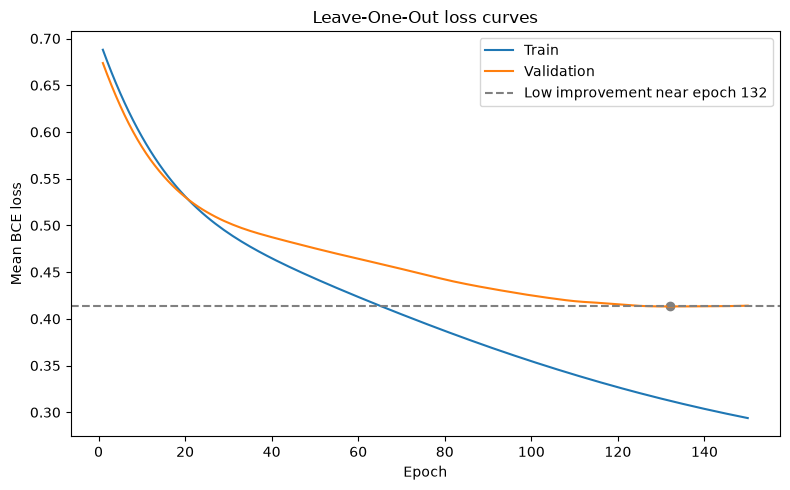

In [100]:
best_config = grid_results.sort_values("mean_val_bce").iloc[0]
train_curves = []
val_curves = []

torch.manual_seed(RANDOM_SEED)
for train_idx, val_idx in loo.split(X_train):
    _, _, train_losses, val_losses = train_one_fold(
        X_train, y_train, train_idx, val_idx,
        hidden_size=int(best_config["hidden_size"]),
        epochs=int(best_config["epochs"]), device=device, record_history=True
    )
    train_curves.append(train_losses)
    val_curves.append(val_losses)

plot_loss_curves(np.mean(train_curves, axis=0), np.mean(val_curves, axis=0))
